# Tarea 3. Visualización y análisis de señales temporales
Señales discretas ($n=1,\dots,9$; $n=1$ es el intervalo 2016–2017 y $n=9$ el 2024–2025) representadas con `stem`.
**Entradas:** `dataset2.csv` y `dataset3.csv` (Tarea 2).

**Métrica de selección** (el enunciado remite a "las métricas definidas en la Tarea 3"; aquí se define explícitamente):
para cada nivel se toma la **mediana de las 9 tasas** de cada departamento; *alta tasa* = departamento con la mediana más alta y *baja tasa* = el de la mediana más baja.
Para el porcentaje oficial: mayor aumento = mayor mediana de $\Delta O$; mayor disminución = menor mediana de $\Delta O$.
Se usa la mediana y no la media porque hay valores extremos por bases muy pequeñas (p. ej. Cauca, técnica profesional, +5.900 % entre 2023 y 2024) que harían que la media premie un solo dato y no un patrón sostenido.
Puede cambiarse con `METRICA = "mean"`.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figuras", exist_ok=True)
METRICA = "median"        # "median" (robusta, por defecto) o "mean"

ds2 = pd.read_csv("dataset2.csv")
ds3 = pd.read_csv("dataset3.csv")
COLS = [c for c in ds2.columns if c not in ("departamento", "nivel")]
n = np.arange(1, len(COLS) + 1)

def tabla_nivel(nivel):
    return ds2[ds2["nivel"] == nivel].set_index("departamento")[COLS]

def stem_plot(ax, y, titulo, color, ylabel):
    marker, stems, base = ax.stem(n, y, basefmt="k-")
    plt.setp(stems, color=color, linewidth=1.5)
    plt.setp(marker, color=color, markersize=6)
    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_xlabel("n (intervalo 2016–2017 a 2024–2025)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(n)
    ax.grid(alpha=0.3)

def seleccionar(tabla):
    m = getattr(tabla, METRICA)(axis=1)
    return m.idxmax(), m.idxmin(), m

def panel(tabla, titulo, ylabel, rol_alto, rol_bajo, col_alto, col_bajo, archivo):
    alto, bajo, m = seleccionar(tabla)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    stem_plot(axes[0], tabla.loc[alto].values, f"{rol_alto}\n{titulo} – {alto}", col_alto, ylabel)
    stem_plot(axes[1], tabla.loc[bajo].values, f"{rol_bajo}\n{titulo} – {bajo}", col_bajo, ylabel)
    plt.tight_layout(); fig.savefig(f"figuras/{archivo}", dpi=150); plt.show()
    return alto, bajo, m

## (a) Nivel universitario

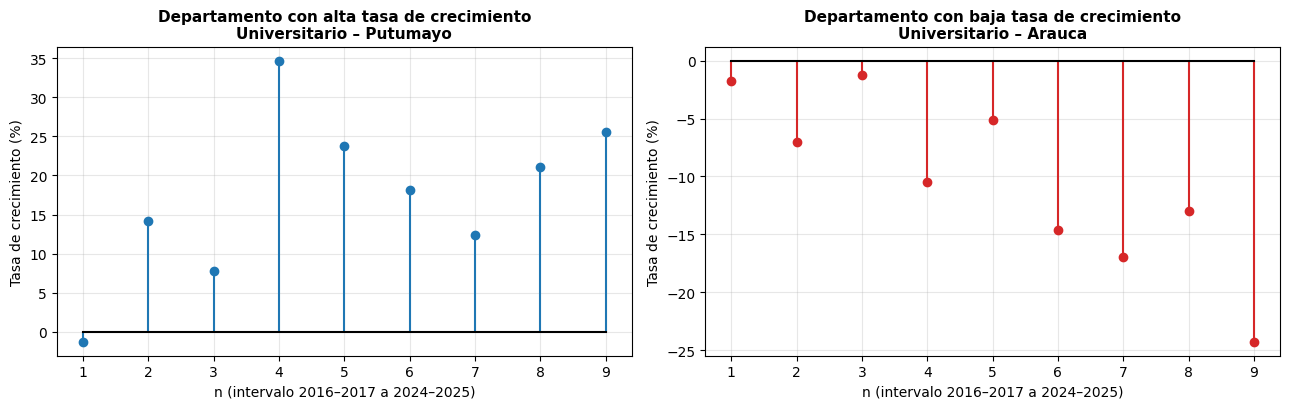

In [3]:
sel_u = panel(tabla_nivel("universitaria"), "Universitario", "Tasa de crecimiento (%)",
              "Departamento con alta tasa de crecimiento", "Departamento con baja tasa de crecimiento",
              "tab:blue", "tab:red", "t3_universitaria.png")

## (b) Nivel tecnológico

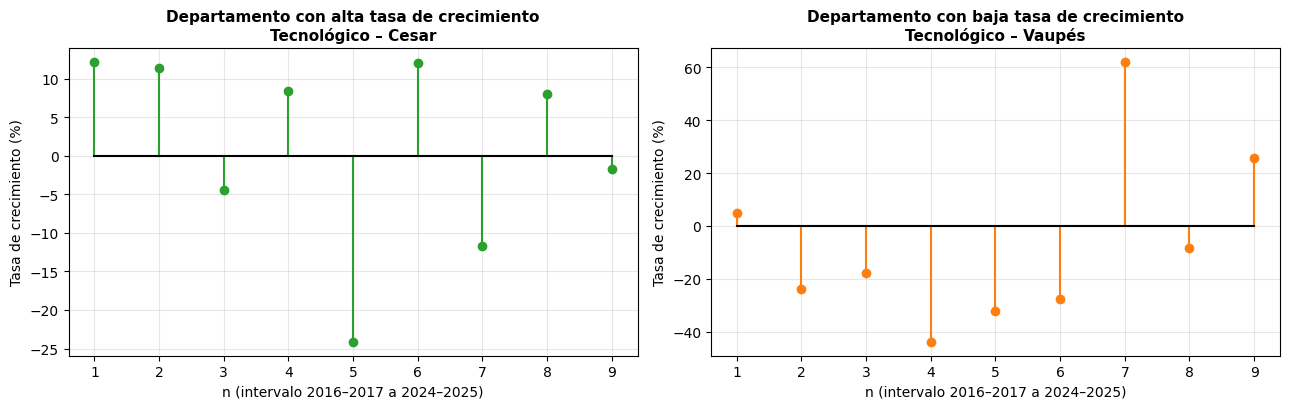

In [4]:
sel_t = panel(tabla_nivel("tecnologica"), "Tecnológico", "Tasa de crecimiento (%)",
              "Departamento con alta tasa de crecimiento", "Departamento con baja tasa de crecimiento",
              "tab:green", "tab:orange", "t3_tecnologica.png")

## (c) Nivel técnico profesional

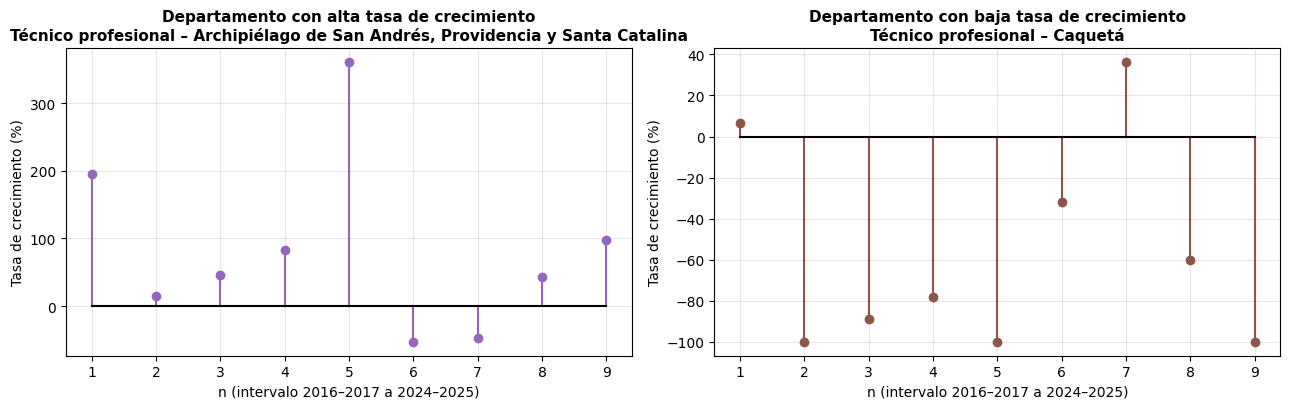

In [5]:
sel_p = panel(tabla_nivel("tecnica"), "Técnico profesional", "Tasa de crecimiento (%)",
              "Departamento con alta tasa de crecimiento", "Departamento con baja tasa de crecimiento",
              "tab:purple", "tab:brown", "t3_tecnica.png")

## (d) Variación interanual del porcentaje oficial

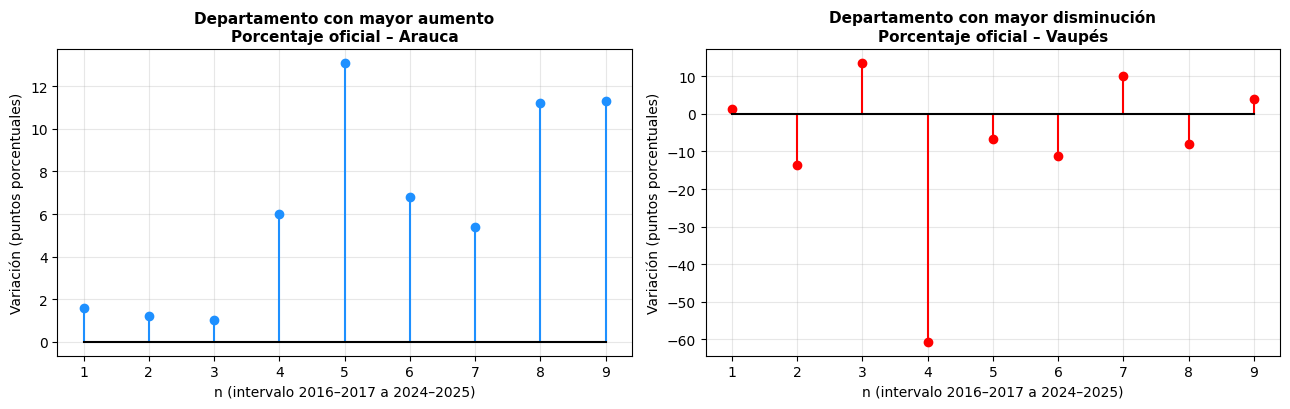

In [6]:
sel_o = panel(ds3.set_index("departamento")[COLS], "Porcentaje oficial", "Variación (puntos porcentuales)",
              "Departamento con mayor aumento", "Departamento con mayor disminución",
              "dodgerblue", "red", "t3_oficial.png")

In [7]:
resumen = pd.DataFrame({
    "serie": ["Universitaria", "Tecnológica", "Técnica profesional", "Porcentaje oficial"],
    "alto / mayor aumento": [s[0] for s in (sel_u, sel_t, sel_p, sel_o)],
    "bajo / mayor disminución": [s[1] for s in (sel_u, sel_t, sel_p, sel_o)],
    f"{METRICA} alto": [round(s[2].max(), 2) for s in (sel_u, sel_t, sel_p, sel_o)],
    f"{METRICA} bajo": [round(s[2].min(), 2) for s in (sel_u, sel_t, sel_p, sel_o)],
})
resumen

,serie,alto / mayor aumento,bajo / mayor disminución,median alto,median bajo
0,Universitaria,Putumayo,Arauca,18.15,-10.50
1,Tecnológica,Cesar,Vaupés,8.07,-17.97
2,Técnica profesional,"Archipiélago de San Andrés, Providencia y Sant...",Caquetá,45.33,-78.16
3,Porcentaje oficial,Arauca,Vaupés,6.00,-6.80


## 5. Exportación
Se guardan (i) la tabla de departamentos seleccionados y (ii) las señales graficadas en formato largo.

In [8]:
TABLAS = {"Universitaria": tabla_nivel("universitaria"), "Tecnológica": tabla_nivel("tecnologica"),
          "Técnica profesional": tabla_nivel("tecnica"), "Porcentaje oficial": ds3.set_index("departamento")[COLS]}
SELECCION = dict(zip(TABLAS, (sel_u, sel_t, sel_p, sel_o)))

resumen.to_csv("tarea3_seleccion.csv", index=False)
print("Guardado tarea3_seleccion.csv:", resumen.shape)
display(pd.read_csv("tarea3_seleccion.csv"))

filas = []
for serie, (alto, bajo, _) in SELECCION.items():
    for rol, dep in (("alto", alto), ("bajo", bajo)):
        for i, col in enumerate(COLS, start=1):
            filas.append([serie, rol, dep, i, col, TABLAS[serie].loc[dep, col]])
series = pd.DataFrame(filas, columns=["serie", "rol", "departamento", "n", "intervalo", "valor"])
series.to_csv("tarea3_series.csv", index=False)
print("Guardado tarea3_series.csv:", series.shape)
pd.read_csv("tarea3_series.csv").head()

Guardado tarea3_seleccion.csv: (4, 5)


,serie,alto / mayor aumento,bajo / mayor disminución,median alto,median bajo
0,Universitaria,Putumayo,Arauca,18.15,-10.50
1,Tecnológica,Cesar,Vaupés,8.07,-17.97
2,Técnica profesional,"Archipiélago de San Andrés, Providencia y Sant...",Caquetá,45.33,-78.16
3,Porcentaje oficial,Arauca,Vaupés,6.00,-6.80


Guardado tarea3_series.csv: (72, 6)


,serie,rol,departamento,n,intervalo,valor
0,Universitaria,alto,Putumayo,1,2016_2017,-1.24
1,Universitaria,alto,Putumayo,2,2017_2018,14.23
2,Universitaria,alto,Putumayo,3,2018_2019,7.84
3,Universitaria,alto,Putumayo,4,2019_2020,34.65
4,Universitaria,alto,Putumayo,5,2020_2021,23.71
